# Phase 1: Data exploration (parts A-C)
A. Sanity checks · B. Base rates · C. How complete the data is at publish time.
Run from the `notebooks/` folder with the project's `.venv` kernel (outputs are saved in the file).

In [1]:
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.load import load

FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

vulns = load("vulnerabilities", ["cve_id", "published", "nvd_status", "assigner", "cvss3_score",
                                 "cvss3_source", "cvss4_score", "cwe_ids", "n_affected_cpes", "n_references"])
kev = load("known_exploited", ["cve_id", "vendor", "date_added"])
sig = load("exploit_signals")
board = load("scoreboard_2026")
vulns["pub_year"] = vulns.published.dt.year
vulns["pub_month"] = vulns.published.dt.month


def snapshot_end(published: pd.Series) -> pd.Series:
    """End of the publish month; June -> end of July (matches the scoreboard)."""
    p = published.dt.to_period("M")
    p = p.where(published.dt.month != 6, p + 1)
    return p.dt.to_timestamp(how="end").dt.normalize()

## A. Sanity checks

== A1. Signals IDs vs vulnerabilities.csv


distinct IDs in signals: 319,691; not in vulnerabilities.csv (rejected): 11,793

== A2. Rows per month in signals (Feb 2025 gap)
month
2024-01    223287
2024-02    237194
2024-03    240515
2024-04    244218
2024-05    248882
2024-06    251955
2024-07    254856
2024-08    257994
2024-09    260504
2024-10    264100
2024-11    268205
2024-12    271574
2025-01    274049
2025-02    264739
2025-03    272403
2025-04    276644
2025-05    280694
2025-06    284326
2025-07    288078
2025-08    291752
2025-09    296005
2025-10    300305
2025-11    303389
2025-12    308066
Jan-25 minus Feb-25 rows: 9,310

== A3. KEV added before publish
KEV entries: 1,484; not in vulnerabilities.csv: 0; added before published: 62
  of those, published 2024-2025: 14


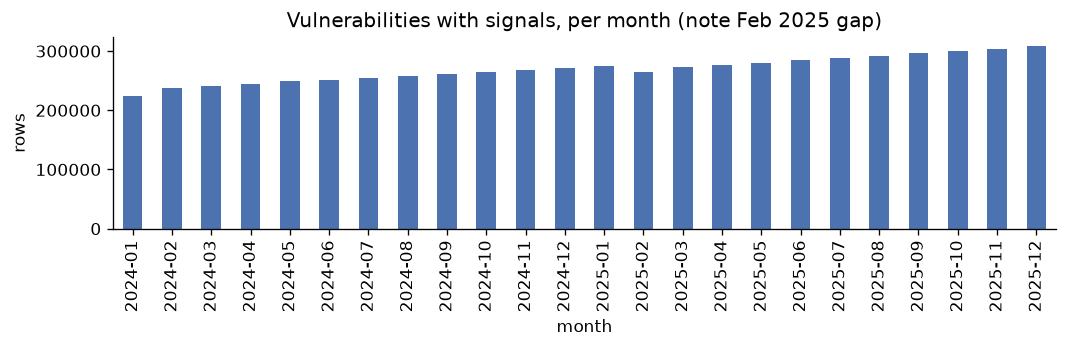

In [2]:
print("== A1. Signals IDs vs vulnerabilities.csv")
sig_ids = pd.Index(sig.cve_id.unique())
missing = sig_ids.difference(vulns.cve_id)
print(f"distinct IDs in signals: {len(sig_ids):,}; not in vulnerabilities.csv (rejected): {len(missing):,}")

print("\n== A2. Rows per month in signals (Feb 2025 gap)")
per_month = sig.groupby("month", observed=True).size()
print(per_month.to_string())
feb_gap = per_month.get("2025-01") - per_month.get("2025-02")
print(f"Jan-25 minus Feb-25 rows: {feb_gap:,}")

fig, ax = plt.subplots(figsize=(9, 3))
per_month.plot.bar(ax=ax, color="#4c72b0")
ax.set_title("Vulnerabilities with signals, per month (note Feb 2025 gap)")
ax.set_ylabel("rows")
fig.tight_layout(); fig.savefig(FIG / "a2_signals_per_month.png")

print("\n== A3. KEV added before publish")
kv = kev.merge(vulns[["cve_id", "published"]], on="cve_id", how="left")
before = kv[kv.date_added < kv.published]
print(f"KEV entries: {len(kv):,}; not in vulnerabilities.csv: {kv.published.isna().sum()}; "
      f"added before published: {len(before)}")
print("  of those, published 2024-2025:", before.published.dt.year.between(2024, 2025).sum())

In [3]:
print("\n== A4. New vulnerabilities missing from that month's signals (cohort Jan-Sep)")
rows = []
for y in (2024, 2025):
    c = vulns[(vulns.pub_year == y) & (vulns.pub_month <= 9)].copy()
    c["snap"] = snapshot_end(c.published).dt.strftime("%Y-%m")
    s = sig[sig.month.astype(str).str.startswith(str(y))][["month", "cve_id"]].copy()
    s["month"] = s.month.astype(str)
    m = c.merge(s, left_on=["cve_id", "snap"], right_on=["cve_id", "month"], how="left", indicator=True)
    r = m.groupby("snap")["_merge"].apply(lambda x: (x == "left_only").mean()).rename("share_missing")
    rows.append(r)
miss = pd.concat(rows)
print(miss.round(3).to_string())
b = board.copy()
print(f"scoreboard 2026 share with no EPSS: {b.epss.isna().mean():.3f}")
print(b.assign(m=b.snapshot_month).groupby("m").epss.apply(lambda x: x.isna().mean()).round(3).to_string())


== A4. New vulnerabilities missing from that month's signals (cohort Jan-Sep)


snap
2024-01    0.047
2024-02    0.022
2024-03    0.019
2024-04    0.021
2024-05    0.095
2024-07    0.055
2024-08    0.010
2024-09    0.027
2025-01    0.448
2025-02    0.233
2025-03    0.082
2025-04    0.024
2025-05    0.005
2025-07    0.010
2025-08    0.007
2025-09    0.024
scoreboard 2026 share with no EPSS: 0.020
m
2026-01    0.010
2026-02    0.003
2026-03    0.036
2026-04    0.026
2026-05    0.005
2026-07    0.006
2026-08    0.025
2026-09    0.037


## B. Base rates

In [4]:
def cohort(y: int) -> pd.DataFrame:
    c = vulns[(vulns.pub_year == y) & (vulns.pub_month <= 9)].copy()
    c["snap"] = snapshot_end(c.published)
    c = c.merge(kev[["cve_id", "date_added"]], on="cve_id", how="left")
    c["kev_at_snap"] = c.date_added <= c.snap
    cutoff = pd.Timestamp(f"{y}-11-04")
    c["label"] = (c.date_added > c.snap) & (c.date_added <= cutoff)
    c["window_days"] = (cutoff - c.snap).dt.days
    return c

print("== B1. Cohort sizes, excluded, positives")
summ = []
for y in (2024, 2025):
    c = cohort(y)
    kept = c[~c.kev_at_snap]
    summ.append(dict(year=y, published=len(c), on_kev_at_snapshot=int(c.kev_at_snap.sum()),
                     cohort=len(kept), positives=int(kept.label.sum()),
                     per_10k=round(kept.label.mean() * 1e4, 1),
                     scaled_K=round(500 * len(kept) / len(board))))
c26 = vulns[(vulns.pub_year == 2026) & (vulns.pub_month <= 9)]
print(pd.DataFrame(summ).to_string(index=False))
print(f"2026 Jan-Sep published in vulnerabilities.csv: {len(c26):,}; scoreboard rows: {len(board):,}; "
      f"difference: {len(c26) - len(board):,}")
in_board = c26.cve_id.isin(board.cve_id)
print("  2026 Jan-Sep not in scoreboard, by nvd_status:",
      c26[~in_board].nvd_status.value_counts().head(6).to_dict())
print("  scoreboard IDs not published Jan-Sep 2026:", (~board.cve_id.isin(c26.cve_id)).sum())

== B1. Cohort sizes, excluded, positives
 year  published  on_kev_at_snapshot  cohort  positives  per_10k  scaled_K
 2024      28902                  66   28836         24      8.3       198
 2025      35366                  88   35278         45     12.8       243
2026 Jan-Sep published in vulnerabilities.csv: 72,794; scoreboard rows: 72,670; difference: 124
  2026 Jan-Sep not in scoreboard, by nvd_status: {'Analyzed': 124, 'Awaiting Analysis': 0, 'Deferred': 0, 'Modified': 0, 'Received': 0, 'Undergoing Analysis': 0}


  scoreboard IDs not published Jan-Sep 2026: 0



== B2. Positives by publish month
              n        pos      window     
year       2024  2025 2024 2025   2024 2025
pub_month                                  
1          2585  4267    4    7    278  277
2          2773  3664    2    5    249  249
3          3305  3982    1    7    218  218
4          3612  4024    1    5    188  188
5          4991  3968    4    6    157  157
6          3072  3671    3    4     96   96
7          3105  3768    1    2     96   96
8          2885  3621    5    5     65   65
9          2508  4313    3    4     35   35


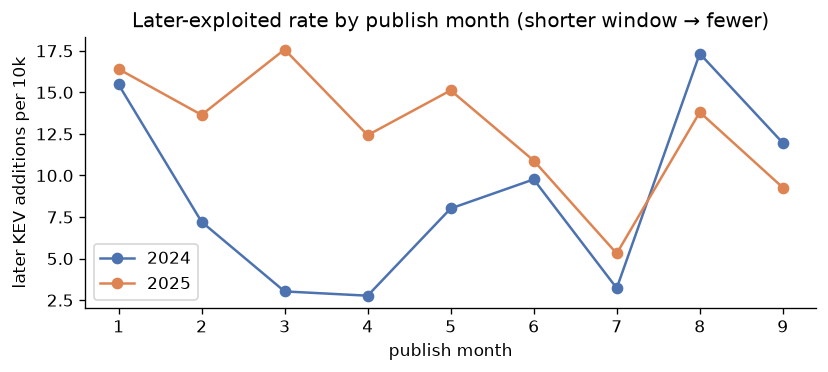

In [5]:
print("\n== B2. Positives by publish month")
bym = []
for y in (2024, 2025):
    k = cohort(y); k = k[~k.kev_at_snap]
    g = k.groupby("pub_month").agg(n=("label", "size"), pos=("label", "sum"), window=("window_days", "first"))
    g["year"] = y
    bym.append(g)
bym = pd.concat(bym).reset_index()
print(bym.pivot(index="pub_month", columns="year", values=["n", "pos", "window"]).to_string())

fig, ax = plt.subplots(figsize=(7, 3.2))
for y, col in ((2024, "#4c72b0"), (2025, "#dd8452")):
    d = bym[bym.year == y]
    ax.plot(d.pub_month, d.pos / d.n * 1e4, marker="o", label=str(y), color=col)
ax.set_xlabel("publish month"); ax.set_ylabel("later KEV additions per 10k")
ax.set_title("Later-exploited rate by publish month (shorter window → fewer)")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "b2_rate_by_month.png")


== B3. Days from publish to KEV (vulns published 2022-2025, listed after publish)
count     546.0
mean       87.0
std       178.0
min         0.0
25%         1.0
50%        10.0
75%        88.0
90%       256.0
max      1198.0
  listed within   7 days: 0.47
  listed within  30 days: 0.61
  listed within  60 days: 0.71
  listed within  90 days: 0.75
  listed within 180 days: 0.85
  listed within 365 days: 0.94
positives only (n=69): median 54 days, p25 34, p75 106


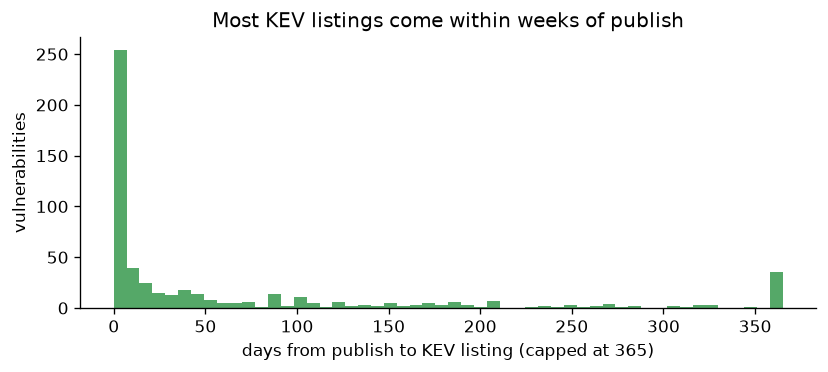

In [6]:
print("\n== B3. Days from publish to KEV (vulns published 2022-2025, listed after publish)")
lag = kv[(kv.published.dt.year.between(2022, 2025)) & (kv.date_added >= kv.published)].copy()
lag["days"] = (lag.date_added - lag.published).dt.days
print(lag.days.describe(percentiles=[.25, .5, .75, .9]).round(0).to_string())
for d in (7, 30, 60, 90, 180, 365):
    print(f"  listed within {d:>3} days: {(lag.days <= d).mean():.2f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(lag.days.clip(upper=365), bins=52, color="#55a868")
ax.set_xlabel("days from publish to KEV listing (capped at 365)"); ax.set_ylabel("vulnerabilities")
ax.set_title("Most KEV listings come within weeks of publish")
fig.tight_layout(); fig.savefig(FIG / "b3_lag_hist.png")

# Of the ones that are NOT zero-days (listed after the snapshot), when are they listed?
pos_lags = []
for y in (2024, 2025):
    k = cohort(y); k = k[k.label]
    pos_lags.append((k.date_added - k.published).dt.days)
pos_lags = pd.concat(pos_lags)
print(f"positives only (n={len(pos_lags)}): median {pos_lags.median():.0f} days, "
      f"p25 {pos_lags.quantile(.25):.0f}, p75 {pos_lags.quantile(.75):.0f}")

## C. How complete the data is, by publish year (decides which features are safe)

== C1. Status by publish year (share)
nvd_status  Analyzed  Awaiting Analysis  Deferred  Modified  Received  Undergoing Analysis
pub_year                                                                                  
2024           0.425               0.00     0.151     0.424      0.00                0.000
2025           0.503               0.00     0.349     0.148      0.00                0.000
2026           0.431               0.07     0.374     0.070      0.05                0.005

== C1b. Fields present by publish year (share)
          has_cvss3  has_cvss4  has_cwe  has_cpes
pub_year                                         
2024          0.996      0.067    0.948     0.849
2025          0.962      0.249    0.957     0.651
2026          0.913      0.315    0.932     0.504

mean n_references: {2024: 2.58, 2025: 2.7, 2026: 3.09}

== C1c. KEV vs not, 2024-2025 (the leak these columns carry)
        analyzed  has_cpes  n_refs  has_cvss3
on_kev                                       

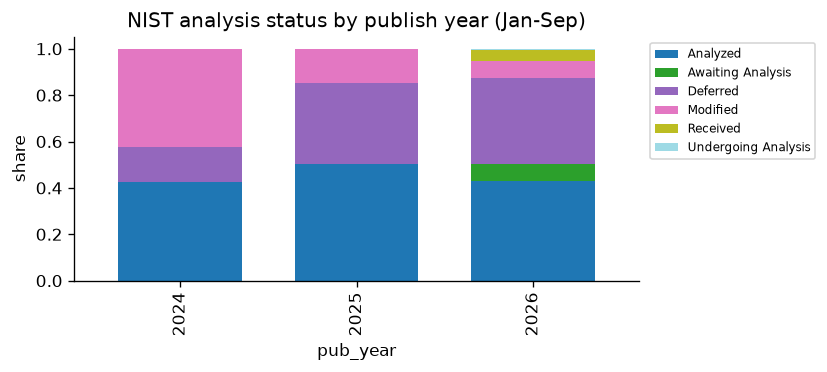

In [7]:
v = vulns[vulns.pub_year.between(2024, 2026) & (vulns.pub_month <= 9)].copy()
v["has_cvss3"] = v.cvss3_score.notna()
v["has_cvss4"] = v.cvss4_score.notna()
v["has_cwe"] = v.cwe_ids.notna() & ~v.cwe_ids.fillna("").str.startswith("NVD-CWE")
v["has_cpes"] = v.n_affected_cpes > 0
print("== C1. Status by publish year (share)")
print(pd.crosstab(v.pub_year, v.nvd_status.astype(str), normalize="index").round(3).to_string())
print("\n== C1b. Fields present by publish year (share)")
print(v.groupby("pub_year")[["has_cvss3", "has_cvss4", "has_cwe", "has_cpes"]].mean().round(3).to_string())
print("\nmean n_references:", v.groupby("pub_year").n_references.mean().round(2).to_dict())

# KEV vs non-KEV within each year: how much do these columns give away?
v = v.merge(kev[["cve_id"]].assign(on_kev=True), on="cve_id", how="left")
v["on_kev"] = v.on_kev.fillna(False).astype(bool)
print("\n== C1c. KEV vs not, 2024-2025 (the leak these columns carry)")
lk = v[v.pub_year <= 2025].groupby("on_kev").agg(
    analyzed=("nvd_status", lambda x: x.isin(["Analyzed", "Modified"]).mean()),
    has_cpes=("has_cpes", "mean"), n_refs=("n_references", "mean"), has_cvss3=("has_cvss3", "mean"))
print(lk.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.2))
st = pd.crosstab(v.pub_year, v.nvd_status.astype(str), normalize="index")
st.plot.bar(stacked=True, ax=ax, colormap="tab20", width=0.7)
ax.set_ylabel("share"); ax.set_title("NIST analysis status by publish year (Jan-Sep)")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "c1_status_by_year.png")


== C2. Who gave the CVSS 3 score
cvss3_from   CISA   NIST   none  vendor (CNA)
pub_year                                     
2024        0.141  0.622  0.004         0.233
2025        0.153  0.369  0.038         0.441
2026        0.144  0.188  0.087         0.580

KEV vs not, 2024-2025:
cvss3_from   CISA   NIST   none  vendor (CNA)
on_kev                                       
False       0.148  0.482  0.023         0.347
True        0.049  0.610  0.000         0.341


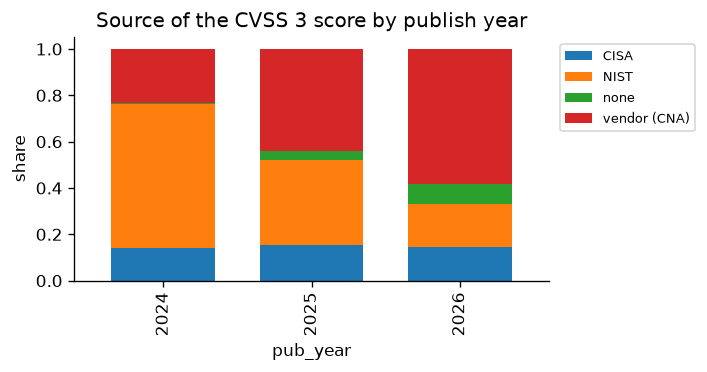

In [8]:
print("\n== C2. Who gave the CVSS 3 score")
CISA = "134c704f-9b21-4f2e-91b3-4a467353bcc0"
src = v.cvss3_source.astype(str).where(v.has_cvss3, "none")
v["cvss3_from"] = "vendor (CNA)"
v.loc[src == "nvd@nist.gov", "cvss3_from"] = "NIST"
v.loc[src == CISA, "cvss3_from"] = "CISA"
v.loc[src == "none", "cvss3_from"] = "none"
cs = pd.crosstab(v.pub_year, v.cvss3_from, normalize="index").round(3)
print(cs.to_string())
print("\nKEV vs not, 2024-2025:")
print(pd.crosstab(v[v.pub_year <= 2025].on_kev, v[v.pub_year <= 2025].cvss3_from, normalize="index").round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 3.2))
cs.plot.bar(stacked=True, ax=ax, width=0.7)
ax.set_ylabel("share"); ax.set_title("Source of the CVSS 3 score by publish year")
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "c2_cvss_source.png")


== C3. Snapshot EPSS / flags vs label (2024-2025 cohorts)


                n  epss_median  epss_missing  any_flag
year label                                            
2024 False  28812       0.0004        0.0438    0.0220
     True      24       0.0004        0.1250    0.3333
2025 False  35233       0.0004        0.0968    0.0215
     True      45       0.0012        0.0444    0.4444

figures written to /Users/takshgirdhar/Desktop/Projects/BreachPoint/outputs/figures


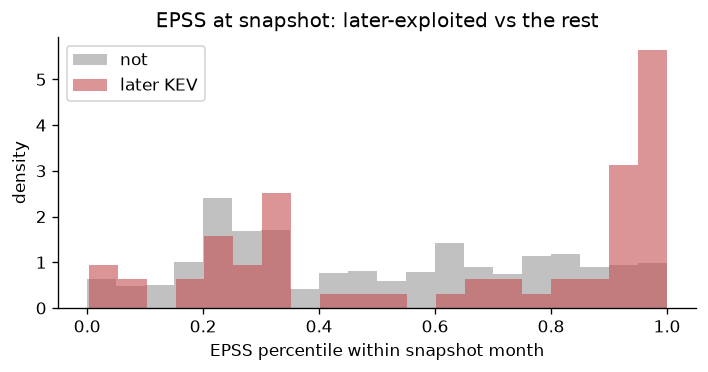

In [9]:
print("\n== C3. Snapshot EPSS / flags vs label (2024-2025 cohorts)")
rows = []
for y in (2024, 2025):
    c = cohort(y); c = c[~c.kev_at_snap].copy()
    c["snap_m"] = c.snap.dt.strftime("%Y-%m")
    s = sig.assign(month=sig.month.astype(str))
    c = c.merge(s.drop(columns="in_kev"), left_on=["cve_id", "snap_m"], right_on=["cve_id", "month"], how="left")
    c["any_flag"] = c[["exploitdb", "metasploit", "nuclei", "poc_github"]].fillna(0).sum(axis=1) > 0
    c["epss_pct"] = c.groupby("snap_m").epss.rank(pct=True)
    rows.append(c.assign(year=y))
cc = pd.concat(rows)
print(cc.groupby(["year", "label"]).agg(n=("cve_id", "size"), epss_median=("epss", "median"),
                                        epss_missing=("epss", lambda x: x.isna().mean()),
                                        any_flag=("any_flag", "mean")).round(4).to_string())
cc.to_parquet(ROOT / "outputs" / "explore_cohorts.parquet", index=False)

fig, ax = plt.subplots(figsize=(6, 3.2))
for lab, col in ((False, "#999999"), (True, "#c44e52")):
    d = cc[cc.label == lab].epss_pct.dropna()
    ax.hist(d, bins=20, density=True, alpha=0.6, color=col, label="later KEV" if lab else "not")
ax.set_xlabel("EPSS percentile within snapshot month"); ax.set_ylabel("density")
ax.set_title("EPSS at snapshot: later-exploited vs the rest"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "c3_epss_vs_label.png")
print("\nfigures written to", FIG)

## What we learned (Sat Nov 7)

**Sanity (A)**
- 11,793 signal IDs are rejected CVEs (expected ~11,800). All 1,484 KEV IDs join to vulnerabilities.csv.
- The 62 KEV-before-publish entries need no special handling: they are on KEV at the snapshot, so the cohort rule drops them.
- **New-CVE signal coverage is poor in Jan 2025 (45% missing) and Feb 2025 (23%)**, vs 1-4% in the 2026 scoreboard.
  The validation set has more missing EPSS than the data we score → keep the rows with EPSS blank (no missing flag: the missing-vs-label link flips between years) and report results with and without Jan-Feb 2025 (decision C3).
- Reconstruction matches the scoreboard: 72,794 published Jan-Sep 2026 minus 124 (all `Analyzed`, i.e. on 2026 KEV at snapshot) = 72,670. Our cohort rule is right.

**Base rates (B)**
- Positives (later KEV, by Nov 4): **24 in 2024 (8.3 per 10k), 45 in 2025 (12.8 per 10k)**. Expect roughly 60-95 in the 2026 scoreboard.
- Scaled K for hits@K: **198 (2024), 243 (2025)**.
- 47% of KEV listings come within 7 days of publish (zero-days, excluded by design). Our positives: median **54 days** (p25 34, p75 106).
- Publish month matters less than expected: even September (35-day window) has 3-4 positives per year.

**Completeness and leakage (C)**
- KEV vulns are 100% analysed and 100% have product lists, vs 74% for the rest (2024-25). In 2026 only 50% have product lists.
  → `nvd_status`, `n_affected_cpes`, `n_references` are confirmed leaky. Excluded.
- CVSS 3 source: NIST scored 61% of KEV vulns vs 48% of others; CISA scored 5% vs 15%. **The source itself leaks**, so NIST- and CISA-sourced scores are excluded.
  Vendor (CNA) scores cover 34% of both groups (no leak) → safe to use, as decided. In 2026, 58% of vulns have a CNA score.
- **EPSS at the snapshot barely separates positives** (median 0.0004 vs 0.0004 in 2024; 0.0012 vs 0.0004 in 2025).
  **Exploit flags do: 33-44% of positives have one vs 2.2% of the rest (15-20× lift).** Most positives (56-67%) have no flag, so they need other signals: vendor, product type, description.